# 초구 예측 — 데이터 확인 & 전처리

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA_PATH = 'pts_pitch_data.xlsx'

STR_COLS = ['gameID', 'pitcher_code', 'batter_code', 'catcher_code', 'PITCH_ID', 'how', 'field_if', 'place_sc', 'runner_sc']

raw = pd.read_excel(DATA_PATH, sheet_name='pts_pitch_2017_2020', dtype={c: str for c in STR_COLS})
pitchers = pd.read_excel(DATA_PATH, sheet_name='pitcher_list',
                         usecols=['pitcher_code', 'pitcher_name', 'pit_cn'],
                         dtype={'pitcher_code': str})
print(raw.shape)

(197102, 69)


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197102 entries, 0 to 197101
Data columns (total 69 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   gameID                          197102 non-null  object 
 1   GYEAR                           197102 non-null  int64  
 2   pit_no                          197102 non-null  int64  
 3   pa_seq                          197102 non-null  int64  
 4   inning                          197102 non-null  int64  
 5   tb                              197102 non-null  object 
 6   bat_team                        197102 non-null  object 
 7   batorder                        197102 non-null  int64  
 8   bat_turn                        197102 non-null  int64  
 9   pa_pitch_no                     197102 non-null  int64  
 10  pitcher_code                    197102 non-null  object 
 11  pitcher_name                    197102 non-null  object 
 12  batter_code     

In [4]:
print(raw.isna().sum()[lambda s: s > 0])

how         146298
field_if    150573
place_sc    146298
dtype: int64


In [5]:
print('키 중복:', raw.duplicated(['gameID', 'pit_no']).sum())

키 중복: 0


In [6]:
print('투수별 투구 수 일치:',
      raw['pitcher_code'].value_counts().sort_index()
      .equals(pitchers.set_index('pitcher_code')['pit_cn'].sort_index()))

투수별 투구 수 일치: True


In [7]:
count = raw['ball_before'].astype(str) + '-' + raw['strike_before'].astype(str)
print(pd.crosstab(raw['pa_pitch_no'].eq(1), count.eq('0-0'),
                  rownames=['pa_pitch_no==1'], colnames=['0-0 카운트']))

0-0 카운트          False  True 
pa_pitch_no==1               
False           145859      0
True               531  50712


pa_pitch_no==1인데 0-0 아님: 531, 0-0인데 pa_pitch_no>1: 0

-> 초구 정의는 0-0 카운트로, pa_pitch_no==1 아님XX

In [8]:
raw.nunique()[lambda s: s == 1]

,0
CROSS_PLATE_Y,1
Y0_KOR,1


CROSS_PLATE_Y, Y0_KOR는 필요없을 듯

원본 `raw`는 그대로 두고, 여기부터는 복사본 `df`만 수정

중간 셀부터 다시 실행할 땐 이 셀부터 다시 실행 (수정 셀은 위에서부터 한 번에)

In [9]:
df = raw.copy()

앞뒤 공백 제거 - ' 6 3 '과 '6 3'이 같은 값이 되도록

In [10]:
for c in ['how', 'field_if', 'place_sc']:
    df[c] = df[c].where(df[c].isna(), df[c].astype(str).str.strip()).replace('', np.nan)

타석이 끝났는데 field_if가 비어 있으면 수비 관여 없는 결과 → '없음'

NaN은 '타석이 안 끝난 공'만 남음

In [11]:
df.loc[df['how'].notna() & df['field_if'].isna(), 'field_if'] = '없음'

In [12]:
print(df[['how', 'field_if', 'place_sc']].notna().sum())
print(df.loc[df['field_if'] == '없음', 'how'].value_counts())
print(df['place_sc'].value_counts().sort_index())

how         50804
field_if    50804
place_sc    50804
dtype: int64
how
BB    4154
HP     631
IB      59
KW      25
KP       3
Name: count, dtype: int64
place_sc
1    10844
2    10297
3    10588
A    15332
B     2237
C      197
E     1297
H        2
R       10
Name: count, dtype: int64


In [13]:
print(df[['speed', 'pz_x', 'pz_y', 'TOP_SZ_KOR', 'BOTTOM_SZ_KOR', 'PITCH_START_SPEED_KOR', 'PITCH_END_SPEED_KOR', 'REPORTED_SPEED_KOR',
           'ARC_BREAK_X_KOR', 'ARC_BREAK_Z_KOR', 'ARC_BREAK_MAGNITUDE_KOR', 'DEFLECTION_BREAK_X_KOR', 'DEFLECTION_BREAK_Z_KOR', 'DEFLECTION_BREAK_MAGNITUDE_KOR']].describe())

               speed           pz_x           pz_y     TOP_SZ_KOR  \
count  197102.000000  197102.000000  197102.000000  197102.000000   
mean      135.107340     110.332280     159.968296       1.049360   
std         9.863908      55.861675      70.980516       0.052403   
min        87.000000      10.000000      10.000000       0.814000   
25%       128.000000      63.000000     104.000000       1.021000   
50%       137.000000     107.000000     168.000000       1.045000   
75%       143.000000     158.000000     216.000000       1.082000   
max       159.000000     220.000000     281.000000       1.342000   

       BOTTOM_SZ_KOR  PITCH_START_SPEED_KOR  PITCH_END_SPEED_KOR  \
count  197102.000000          197102.000000        197102.000000   
mean        0.494562             135.141340           124.684669   
std         0.042065               9.943645             8.867908   
min         0.323000              87.330000            79.550000   
25%         0.460000             128.2

In [14]:
print(df[['BREAK_ANGLE', 'SPIN_ANGLE', 'SPIN_RATE', 'CROSS_PLATE_X_CM', 'CROSS_PLATE_Z_CM',
           'X0_KOR', 'Z0_KOR', 'VX0_KOR', 'VY0_KOR', 'VZ0_KOR', 'AX_KOR', 'AY_KOR', 'AZ_KOR']].describe())

         BREAK_ANGLE     SPIN_ANGLE      SPIN_RATE  CROSS_PLATE_X_CM  \
count  197102.000000  197102.000000  197102.000000     197102.000000   
mean      127.307981     186.937513    1834.073551          0.780632   
std        72.758858      62.383492     731.114171         26.792467   
min         0.002031       0.024048       0.000000       -156.460000   
25%        79.557100     151.541430    1292.000000        -17.140000   
50%       118.120000     200.620640    1997.000000          1.020000   
75%       145.411500     221.551464    2397.000000         18.700000   
max       359.999000     359.999115    4595.000000        224.430000   

       CROSS_PLATE_Z_CM         X0_KOR         Z0_KOR        VX0_KOR  \
count     197102.000000  197102.000000  197102.000000  197102.000000   
mean          71.674385      -0.288862       1.706107       0.911817   
std           30.165899       0.448220       0.206569       1.616182   
min         -100.910000      -1.342000       0.656000      -4.9

SPIN_RATE==0 ??

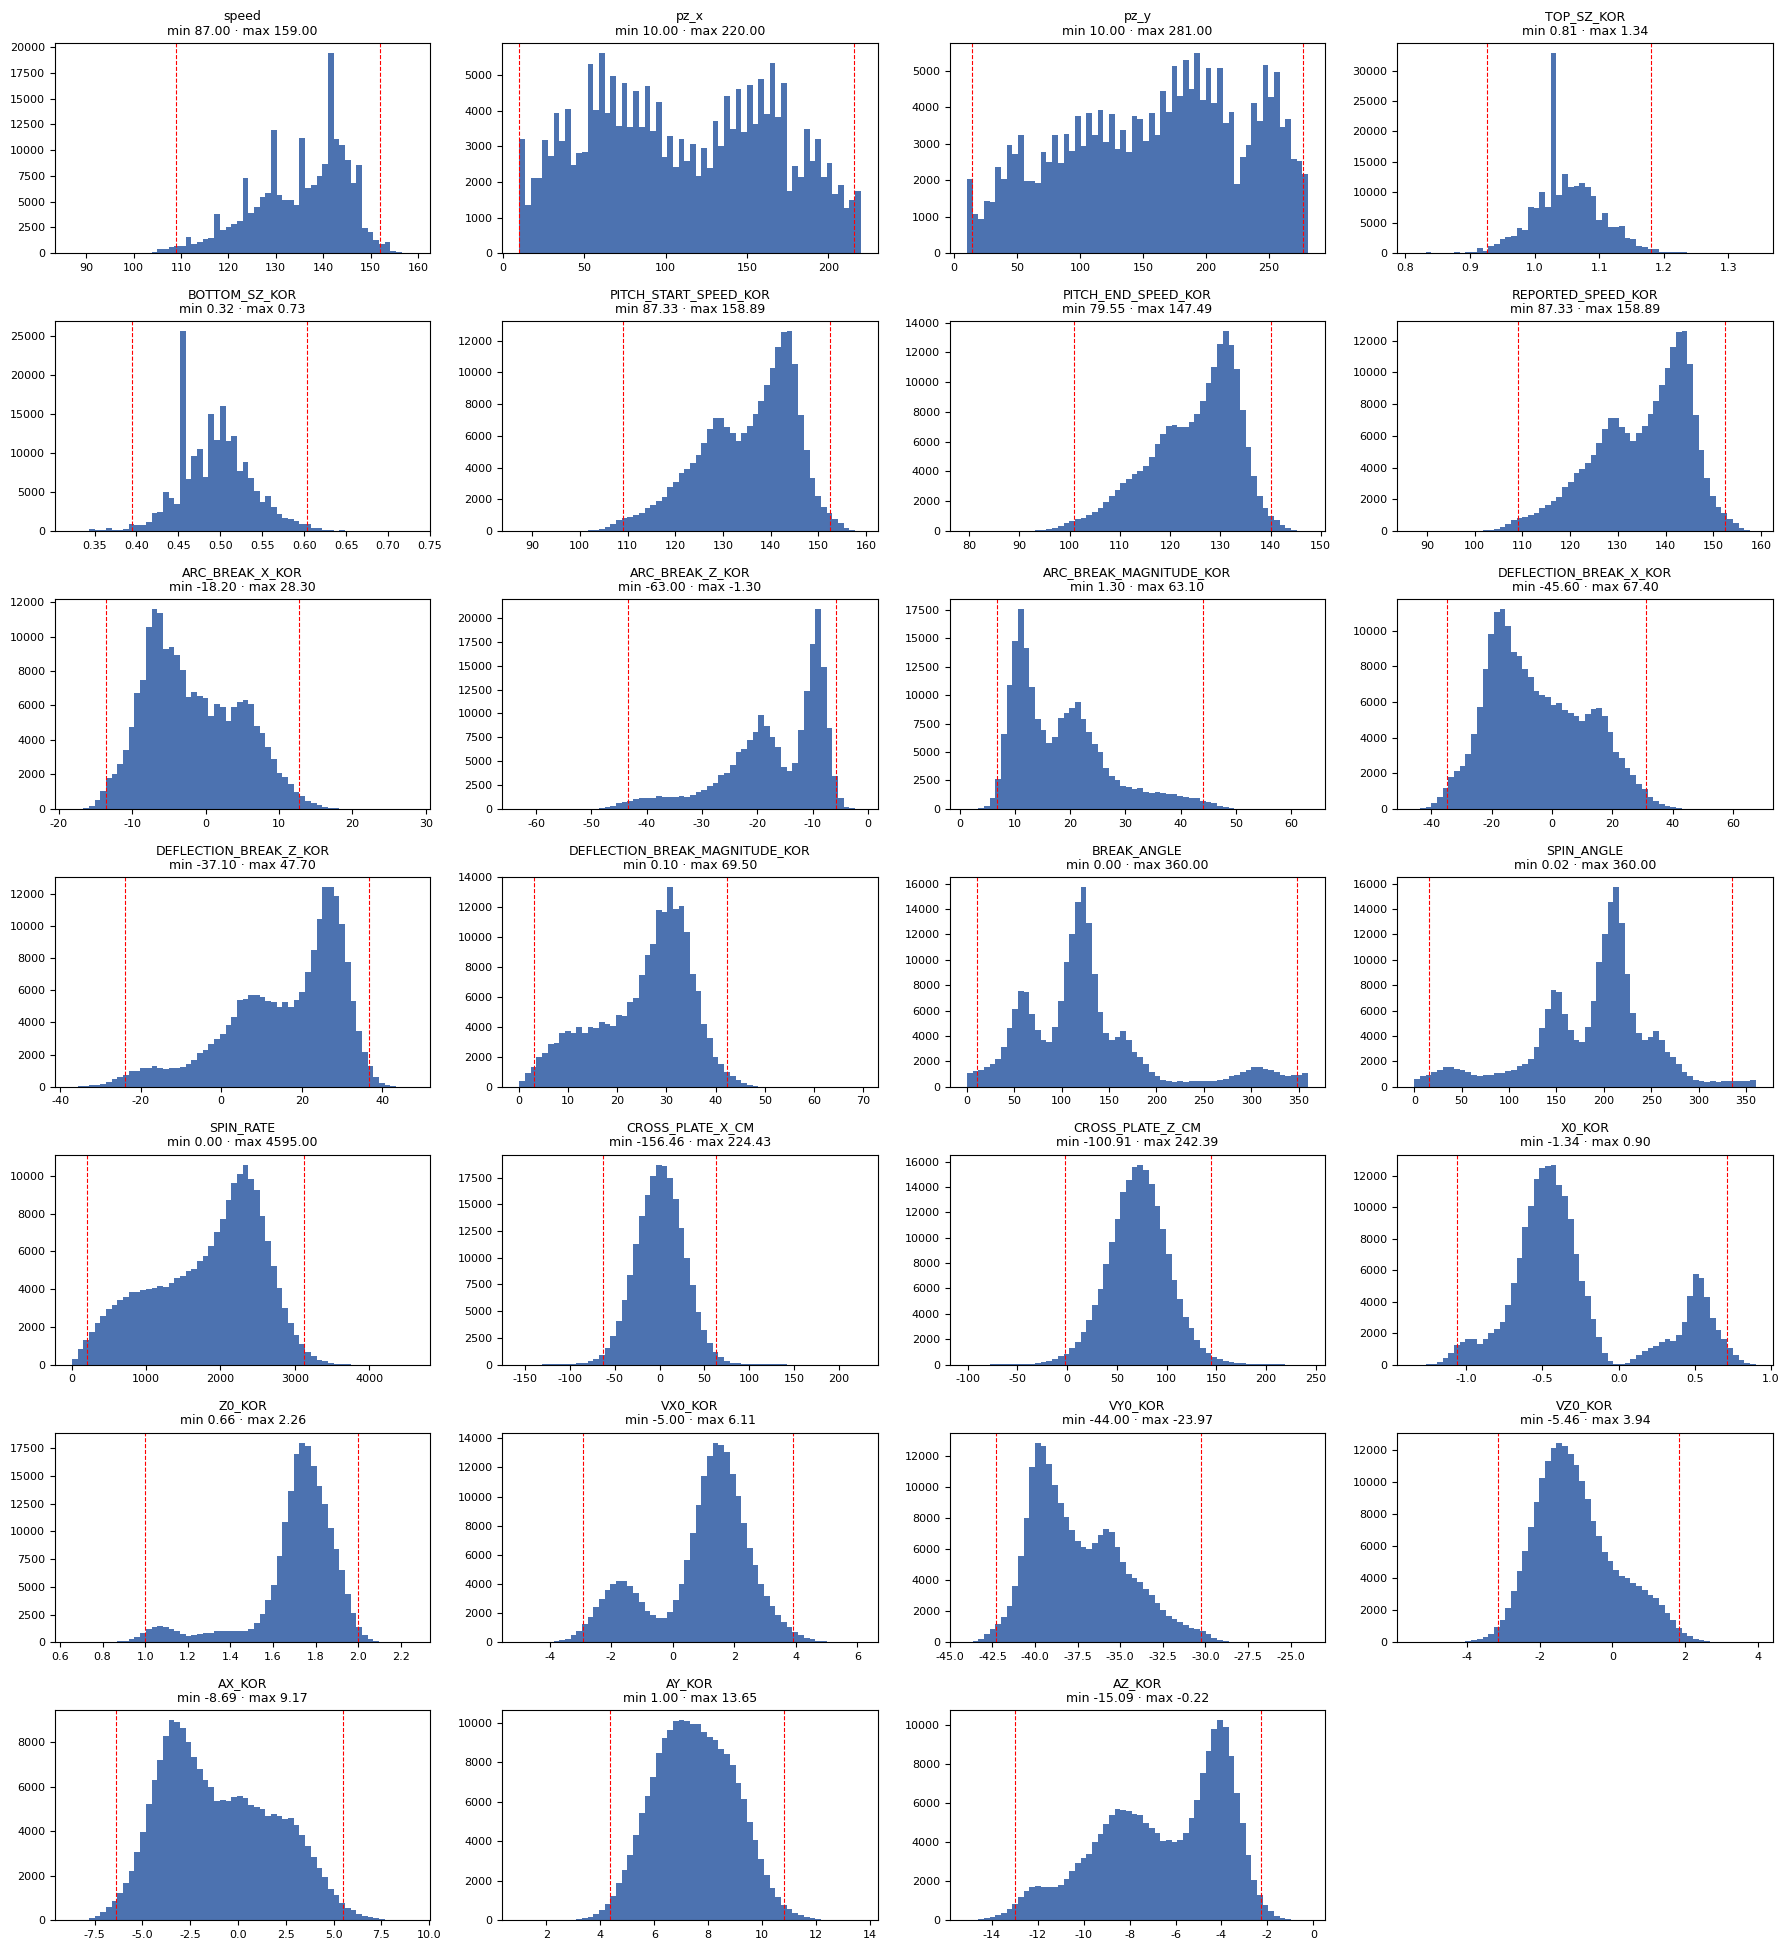

In [15]:
plt.rcParams["axes.unicode_minus"] = False

cols = ['speed', 'pz_x', 'pz_y', 'TOP_SZ_KOR', 'BOTTOM_SZ_KOR', 'PITCH_START_SPEED_KOR', 'PITCH_END_SPEED_KOR', 'REPORTED_SPEED_KOR',
        'ARC_BREAK_X_KOR', 'ARC_BREAK_Z_KOR', 'ARC_BREAK_MAGNITUDE_KOR', 'DEFLECTION_BREAK_X_KOR', 'DEFLECTION_BREAK_Z_KOR', 'DEFLECTION_BREAK_MAGNITUDE_KOR',
        'BREAK_ANGLE', 'SPIN_ANGLE', 'SPIN_RATE', 'CROSS_PLATE_X_CM', 'CROSS_PLATE_Z_CM',
        'X0_KOR', 'Z0_KOR', 'VX0_KOR', 'VY0_KOR', 'VZ0_KOR', 'AX_KOR', 'AY_KOR', 'AZ_KOR']

ncol = 4
nrow = int(np.ceil(len(cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, nrow * 2.8))

for ax, col in zip(axes.flat, cols):
    s = df[col].dropna()
    ax.hist(s, bins=60, color="#4C72B0")
    lo, hi = s.quantile([0.01, 0.99])
    ax.axvline(lo, color="red", ls="--", lw=0.8)   # 하위 1%
    ax.axvline(hi, color="red", ls="--", lw=0.8)   # 상위 1%
    ax.set_title(f"{col}\nmin {s.min():.2f} · max {s.max():.2f}", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[len(cols):]:   # 남는 칸 지우기
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
g = df.groupby(["pitcher_code", "pitch_stuff"])
for col in ["PITCH_START_SPEED_KOR", "SPIN_RATE"]:
    med = g[col].transform("median")
    mad = g[col].transform(lambda s: (s - s.median()).abs().median()) * 1.4826
    df[col + "_med"] = med
    df[col + "_z"] = (df[col] - med) / mad.replace(0, np.nan)  # 공이 아주 적은 그룹은 MAD=0 → z를 NaN으로

# 타석 구분: 타자가 바뀌거나 앞 공에서 타석이 끝나면 새 타석
# (pa_pitch_no==1로 자르면 대타·빠진 공 때문에 1구가 없는 타석이 앞 타석에 붙어, 461개 타석에 타자가 2명 섞임)
s = df.sort_values(["gameID", "pit_no"])
prev = s.groupby("gameID")[["batter_code", "how"]].shift()
new_pa = prev["batter_code"].isna() | (prev["batter_code"] != s["batter_code"]) | prev["how"].notna()
df["pa_id"] = new_pa.cumsum()
df["ib_pa"] = df.groupby("pa_id")["how"].transform(lambda s: (s == "IB").any())

show = ["gameID", "pit_no", "pitcher_name", "pitch_stuff", "speed", "PITCH_START_SPEED_KOR", "PITCH_START_SPEED_KOR_med",
        "SPIN_RATE", "SPIN_RATE_med", "DEFLECTION_BREAK_X_KOR", "DEFLECTION_BREAK_Z_KOR",
        "ball_before", "strike_before", "pit_result", "how", "ib_pa"]

직구 구속 확인

분포 + 자기 평균보다 15km/h 넘게 느린 공

In [17]:
fast = df[df["pitch_stuff"] == "FAST"]
print(fast["PITCH_START_SPEED_KOR"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).round(1))

slow = fast[fast["PITCH_START_SPEED_KOR"] < fast["PITCH_START_SPEED_KOR_med"] - 15]
print(len(slow), "개 / 고의4구 타석:", slow["ib_pa"].sum())

count    95620.0
mean       142.7
std          4.4
min         87.3
0.1%       125.0
1%         132.6
50%        142.9
99%        153.7
99.9%      156.2
max        158.9
Name: PITCH_START_SPEED_KOR, dtype: float64
81 개 / 고의4구 타석: 57


In [18]:
fast = df[(df["pitch_stuff"] == "FAST") & (~df["ib_pa"])]

slow = fast[fast["PITCH_START_SPEED_KOR"] < fast["PITCH_START_SPEED_KOR_med"] - 15]
print(len(slow), "개")
slow.sort_values("PITCH_START_SPEED_KOR")[show]

24 개


,gameID,pit_no,pitcher_name,pitch_stuff,speed,PITCH_START_SPEED_KOR,PITCH_START_SPEED_KOR_med,SPIN_RATE,SPIN_RATE_med,DEFLECTION_BREAK_X_KOR,DEFLECTION_BREAK_Z_KOR,ball_before,strike_before,pit_result,how,ib_pa
191388,20201006KTLT0,40,박세웅,FAST,93,94.98,143.115,1184,2196.5,-9.6,21.9,0,1,B,NaN,False
25440,20170707OBNC0,158,장현식,FAST,109,108.67,145.470,1334,2269.5,-16.2,16.7,0,1,B,NaN,False
2977,20170414SSLT0,91,박진형,FAST,111,109.22,141.120,1745,2225.0,-16.1,24.9,0,0,B,NaN,False
27086,20170713NCHT0,63,장현식,FAST,110,110.29,145.470,1497,2269.5,-14.7,20.6,0,1,B,NaN,False
108712,20190510LTSS0,190,김원중,FAST,141,115.22,143.170,1514,2475.0,16.6,-19.1,0,0,B,NaN,False
63156,20180524KTHT0,226,고영표,FAST,135,117.05,134.590,1427,1569.0,-18.4,-14.0,0,0,B,NaN,False
27096,20170713NCHT0,73,장현식,FAST,119,118.51,145.470,1403,2269.5,-10.4,19.5,0,1,B,NaN,False
119984,20190616KTSS0,155,원태인,FAST,120,119.35,141.150,2095,2395.0,-10.0,31.7,3,0,T,NaN,False
27131,20170713NCHT0,108,장현식,FAST,121,120.81,145.470,2046,2269.5,-10.4,30.0,1,2,B,NaN,False
143690,20190914SSNC0,169,이재학,FAST,121,120.97,137.240,2057,2340.0,-32.7,-0.5,0,0,B,NaN,False


108712 김원중, 63156 고영표, 47677 구창모, 129501 양현종 - speed와 트래킹 초속 차이 큼

108712 김원중, 47677 구창모, 143690 이재학, 63156 고영표 - 직구인데 Z축 움직임 마이너스

In [19]:
flag_speed_gap = [
    ("20190510LTSS0", 190),   # 108712 김원중
    ("20180524KTHT0", 226),   # 63156  고영표
    ("20180316LGNC0", 6),     # 47677  구창모
    ("20190718LTHT0", 135),   # 129501 양현종
]

flag_fast_neg_z = [
    ("20190510LTSS0", 190),   # 108712 김원중
    ("20180316LGNC0", 6),     # 47677  구창모
    ("20190914SSNC0", 169),   # 143690 이재학
    ("20180524KTHT0", 226),   # 63156  고영표
]

key = pd.Series(list(zip(df["gameID"], df["pit_no"])), index=df.index)
df["flag_speed_gap"] = key.isin(flag_speed_gap)
df["flag_fast_neg_z"] = key.isin(flag_fast_neg_z)
df["flag_any"] = df["flag_speed_gap"] | df["flag_fast_neg_z"]

회전수 확인

극단값 + 같은 투수·구종 안에서 튀는 공

In [20]:
print(df.groupby("pitch_stuff")["SPIN_RATE"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).round(0))

extreme = df[(df["SPIN_RATE"] == 0) | (df["SPIN_RATE"] > 4000)]
odd_spin = df[df["SPIN_RATE_z"].abs() > 5]
print("극단값", len(extreme), "개 / 투수·구종 기준 튀는 공", len(odd_spin), "개")
pd.concat([extreme, odd_spin]).drop_duplicates()[show].sort_values("SPIN_RATE")

               count    mean    std    min   0.1%      1%     50%     99%  \
pitch_stuff                                                                 
CHUP         26172.0  1808.0  401.0  217.0  572.0   841.0  1818.0  2687.0   
CURV         16134.0  1313.0  466.0   16.0   78.0   237.0  1345.0  2255.0   
CUTT          1108.0  1160.0  370.0  212.0  250.0   375.0  1140.0  2078.0   
FAST         95620.0  2370.0  373.0  413.0  904.0  1356.0  2376.0  3224.0   
FORK         14864.0  1287.0  488.0   19.0   70.0   195.0  1317.0  2382.0   
KNUC           139.0   606.0  370.0   52.0   54.0    71.0   556.0  1768.0   
SINK            56.0  1612.0  247.0  744.0  766.0   961.0  1610.0  2010.0   
SLID         33917.0   800.0  396.0    0.0   31.0    90.0   767.0  1812.0   
TWOS          9092.0  2050.0  428.0   47.0  344.0   826.0  2122.0  2791.0   

              99.9%     max  
pitch_stuff                  
CHUP         2929.0  4595.0  
CURV         2539.0  4267.0  
CUTT         2418.0  2581.0  
FA

,gameID,pit_no,pitcher_name,pitch_stuff,speed,PITCH_START_SPEED_KOR,PITCH_START_SPEED_KOR_med,SPIN_RATE,SPIN_RATE_med,DEFLECTION_BREAK_X_KOR,DEFLECTION_BREAK_Z_KOR,ball_before,strike_before,pit_result,how,ib_pa
122856,20190623SSHH0,301,우규민,SLID,129,128.98,128.210,0,572.0,0.0,-0.1,1,2,F,NaN,False
79915,20180726NCLT0,252,노경은,CURV,111,111.22,113.620,215,1621.0,-2.4,-3.1,1,2,B,NaN,False
47677,20180316LGNC0,6,구창모,FAST,137,122.26,143.060,413,2474.5,-1.9,-6.4,1,2,B,NaN,False
185723,20200915LTWO0,127,노경은,CURV,109,107.87,113.620,449,1621.0,8.0,1.3,0,2,B,NaN,False
147262,20190930LTLG0,156,박세웅,CURV,123,122.54,118.425,503,1779.5,-6.1,5.0,0,0,T,NaN,False
178323,20200815WOLT0,56,노경은,CURV,116,115.47,113.620,548,1621.0,5.8,6.7,0,1,H,FF,False
85909,20180816NCKT0,146,이재학,CHUP,124,122.15,122.150,571,2077.0,-8.7,0.1,0,0,B,NaN,False
182533,20200903HTLT0,32,노경은,CURV,118,118.02,113.620,582,1621.0,2.1,8.9,0,0,B,NaN,False
174801,20200802HTLT0,156,노경은,CURV,117,116.55,113.620,586,1621.0,-1.8,9.2,0,0,T,NaN,False
174752,20200802HTLT0,60,노경은,CURV,116,114.72,113.620,590,1621.0,2.2,9.3,0,0,B,NaN,False


122856 우규민, 61972 고영표, 180518 최성영, 86528 김범수 - 회전수·무브먼트 측정 오류 (회전수 0 또는 4,000 이상)

71713 김태훈, 83403 주권, 182800 조상우, 192123 이민우, 69139 장현식 - 직구·투심인데 회전수만 낮게 측정

In [21]:
flag_track_error = [
    ("20190623SSHH0", 301),   # 122856 우규민
    ("20180519NCKT0", 51),    # 61972  고영표
    ("20200823NCKT0", 30),    # 180518 최성영
    ("20180907HHKT0", 209),   # 86528  김범수
]

flag_spin_low = [
    ("20180621WOOB0", 34),    # 71713  김태훈
    ("20180807KTNC0", 275),   # 83403  주권
    ("20200903WOHH0", 313),   # 182800 조상우
    ("20201008HHHT0", 6),     # 192123 이민우
    ("20180612LGNC0", 142),   # 69139  장현식
]

df["flag_track_error"] = key.isin(flag_track_error)
df["flag_spin_low"] = key.isin(flag_spin_low)
df["flag_any"] = df[["flag_speed_gap", "flag_fast_neg_z", "flag_track_error", "flag_spin_low"]].any(axis=1)

단위 통일

In [22]:
df["X0_CM"] = df["X0_KOR"] * 100
df["Z0_CM"] = df["Z0_KOR"] * 100

좌투수 뒤집기

좌/우투수 부호 반대 -> 투수 기준 팔 쪽을 +로 통일

릴리스가 1루 쪽이면 좌투수

In [23]:
lhp = df.groupby("pitcher_code")["X0_KOR"].transform("median") > 0
df["p_throws"] = np.where(lhp, "L", "R")
arm = np.where(lhp, 1, -1)

df["X0_CM_arm"]       = df["X0_CM"] * arm
df["VX0_arm"]         = df["VX0_KOR"] * arm
df["AX_arm"]          = df["AX_KOR"] * arm
df["ARC_BREAK_X_arm"] = df["ARC_BREAK_X_KOR"] * arm
df["DEFL_BREAK_X_arm"] = df["DEFLECTION_BREAK_X_KOR"] * arm
df["SPIN_ANGLE_arm"]  = np.where(lhp, (360 - df["SPIN_ANGLE"]) % 360, df["SPIN_ANGLE"])

좌/우타자 부호 반대 -> 타자 기준 몸쪽 +로 통일

In [24]:
df["plate_x_in_CM"] = df["CROSS_PLATE_X_CM"] * np.where(df["STANCE"] == "R", -1, 1)

In [25]:
df["p_throws"].value_counts()

,count
p_throws,
R,155157
L,41945


In [26]:
print(df.groupby("p_throws")["pitcher_name"].unique())

p_throws
L                  [백정현, 구창모, 최성영, 양현종, 김성민, 함덕주, 김범수]
R    [고영표, 김재윤, 김진성, 이용찬, 우규민, 서진용, 이재학, 김원중, 장현식, ...
Name: pitcher_name, dtype: object


In [27]:
fast = df[df["pitch_stuff"] == "FAST"]
pairs = {
    "X0_CM": "X0_CM_arm",
    "VX0_KOR": "VX0_arm",
    "AX_KOR": "AX_arm",
    "ARC_BREAK_X_KOR": "ARC_BREAK_X_arm",
    "DEFLECTION_BREAK_X_KOR": "DEFL_BREAK_X_arm",
    "SPIN_ANGLE": "SPIN_ANGLE_arm",
}
check = pd.DataFrame({
    (before, "전"): fast.groupby("p_throws")[before].median() for before in pairs
} | {
    (before, "후"): fast.groupby("p_throws")[after].median() for before, after in pairs.items()
}).T.sort_index().round(2)
check

p_throws                       L       R
ARC_BREAK_X_KOR        전    6.10   -6.00
                       후    6.10    6.00
AX_KOR                 전    3.26   -3.24
                       후    3.26    3.24
DEFLECTION_BREAK_X_KOR 전   16.20  -15.70
                       후   16.20   15.70
SPIN_ANGLE             전  150.64  210.40
                       후  209.36  210.40
VX0_KOR                전   -1.93    1.82
                       후   -1.93   -1.82
X0_CM                  전   50.10  -47.20
                       후   50.10   47.20

In [28]:
for before, after in pairs.items():
    if before == "SPIN_ANGLE":
        continue
    print(f"{after:18s}", np.allclose(df[before].abs(), df[after].abs()))

X0_CM_arm          True
VX0_arm            True
AX_arm             True
ARC_BREAK_X_arm    True
DEFL_BREAK_X_arm   True


In [29]:
hp = df[df["how"] == "HP"]
print("몸에 맞는 공", len(hp), "개 / plate_x_in_CM > 0 비율:", (hp["plate_x_in_CM"] > 0).mean().round(3))
print(hp.groupby("STANCE")[["CROSS_PLATE_X_CM", "plate_x_in_CM"]].median().round(1))

몸에 맞는 공 631 개 / plate_x_in_CM > 0 비율: 0.998
        CROSS_PLATE_X_CM  plate_x_in_CM
STANCE                                 
L                   57.8           57.8
R                  -59.8           59.8


SPIN_ANGLE 변환

sin·cos으로 -> 359°와 1°가 가깝게 인식

In [30]:
rad = np.radians(df["SPIN_ANGLE_arm"])
df["spin_axis_sin"] = np.sin(rad)
df["spin_axis_cos"] = np.cos(rad)

df[["SPIN_ANGLE_arm", "spin_axis_sin", "spin_axis_cos"]].describe().round(2)

,SPIN_ANGLE_arm,spin_axis_sin,spin_axis_cos
count,197102.00,197102.00,197102.00
mean,196.38,-0.34,-0.57
std,60.59,0.53,0.53
min,0.00,-1.00,-1.00
25%,189.07,-0.69,-0.92
50%,209.10,-0.48,-0.80
75%,225.02,-0.15,-0.43
max,359.99,1.00,1.00


In [31]:
back = np.degrees(np.arctan2(df["spin_axis_sin"], df["spin_axis_cos"])) % 360
print(np.allclose(back, df["SPIN_ANGLE_arm"] % 360, atol=1e-6))

True


In [32]:
cols = ['GYEAR', 'inning', 'tb', 'bat_team', 'batorder', 'bat_turn', 'pa_pitch_no', 'STANCE',
        'p_throws', 'pitch_stuff', 'pit_result', 'how', 'place_sc', 'strike_before', 'ball_before',
        'out_cn', 'runner_sc', 'runner_cn', 'base1', 'base2', 'base3', 'VENUE_ID']

for col in cols:
    print(f"\n===== {col} =====")
    print(df.groupby(col, dropna=False).size().to_string())


===== GYEAR =====
GYEAR
2017    47532
2018    48660
2019    51341
2020    49569

===== inning =====
inning
1     27031
2     25294
3     25163
4     24620
5     22940
6     20789
7     18175
8     17112
9     14481
10     1061
11      327
12      109

===== tb =====
tb
B    97513
T    99589

===== bat_team =====
bat_team
HH    19030
HT    20643
KT    20740
LG    19963
LT    17338
NC    20236
OB    19509
SK    21750
SS    19264
WO    18629

===== batorder =====
batorder
1    24260
2    23453
3    23073
4    22557
5    22162
6    21611
7    20954
8    19912
9    19120

===== bat_turn =====
bat_turn
1    184736
2     10474
3      1491
4       387
5        12
6         2

===== pa_pitch_no =====
pa_pitch_no
1     51243
2     44995
3     36990
4     28056
5     18603
6     10052
7      4289
8      1786
9       689
10      255
11       95
12       31
13       12
14        5
15        1

===== STANCE =====
STANCE
L     83676
R    113426

===== p_throws =====
p_throws
L     41945
R    155157


out_cn=4 ????

In [33]:
fix_out = df["out_cn"] == 4
print(df.loc[fix_out, ["gameID", "pit_no", "batter_name", "out_cn"]])

           gameID  pit_no batter_name  out_cn
57  20170331LTNC0     249          번즈       4
58  20170331LTNC0     250          번즈       4
59  20170331LTNC0     251          번즈       4


In [34]:
df[df["gameID"] == "20170331LTNC0"][
    ["pit_no", "inning", "tb", "batter_name", "pitcher_name", "pa_pitch_no",
     "ball_before", "strike_before", "out_cn", 'base1', 'base2', 'base3', 'away_score', 'home_score', "pit_result", "how"]].head(20)

,pit_no,inning,tb,batter_name,pitcher_name,pa_pitch_no,ball_before,strike_before,out_cn,base1,base2,base3,away_score,home_score,pit_result,how
57,249,8,T,번즈,김진성,1,0,0,4,0,1,0,3,6,S,NaN
58,250,8,T,번즈,김진성,2,0,1,4,0,1,0,3,6,S,NaN
59,251,8,T,번즈,김진성,3,0,2,4,0,1,0,3,6,B,NaN
60,252,8,T,번즈,김진성,4,1,2,1,0,0,0,4,6,B,NaN
61,253,8,T,번즈,김진성,5,2,2,1,0,0,0,4,6,B,NaN
62,254,8,T,번즈,김진성,6,3,2,1,0,0,0,4,6,T,KK
63,255,8,T,손아섭,김진성,1,0,0,2,0,0,0,4,6,T,NaN
64,256,8,T,손아섭,김진성,2,0,1,2,0,0,0,4,6,S,NaN
65,257,8,T,손아섭,김진성,3,0,2,2,0,0,0,4,6,S,KK


out_cn==4인 경우 이후 타석까지 모두 번즈 타석으로 확인하여 1로 변환

In [35]:
df.loc[fix_out, "out_cn"] = 1

print(df["out_cn"].value_counts().sort_index())
df[(df["gameID"] == "20170331LTNC0") & (df["pit_no"].between(249, 257))][
    ["pit_no", "batter_name", "pa_pitch_no", "ball_before", "strike_before", "out_cn", "pit_result", "how", "place_sc"]]

out_cn
0    67052
1    66110
2    63940
Name: count, dtype: int64


,pit_no,batter_name,pa_pitch_no,ball_before,strike_before,out_cn,pit_result,how,place_sc
57,249,번즈,1,0,0,1,S,NaN,NaN
58,250,번즈,2,0,1,1,S,NaN,NaN
59,251,번즈,3,0,2,1,B,NaN,NaN
60,252,번즈,4,1,2,1,B,NaN,NaN
61,253,번즈,5,2,2,1,B,NaN,NaN
62,254,번즈,6,3,2,1,T,KK,2
63,255,손아섭,1,0,0,2,T,NaN,NaN
64,256,손아섭,2,0,1,2,S,NaN,NaN
65,257,손아섭,3,0,2,2,S,KK,3


볼카운트 이상 확인 1

삼진인데 2스트라이크 아닌 공

In [36]:
mask = df["how"].isin(["KK", "KN", "KW", "KP", "KB"]) & (df["strike_before"] != 2)
print(f"{mask.sum()}건")
df[mask][["gameID", "pit_no", "batter_name", "ball_before", "strike_before", "pit_result", "how"]]

1건


,gameID,pit_no,batter_name,ball_before,strike_before,pit_result,how
74836,20180704SSKT0,267,박한이,1,1,S,KK


In [37]:
cols = ["gameID", "pit_no", "inning", "tb", "batorder", "bat_turn", "batter_name", "pitcher_name",
        "pa_seq", "pa_pitch_no", "ball_before", "strike_before", "out_cn", "base1", "base2", "base3",
        "pit_result", "how"]
df[(df["gameID"] == "20180704SSKT0") & (df["pit_no"].between(260, 270))][cols]

,gameID,pit_no,inning,tb,batorder,bat_turn,batter_name,pitcher_name,pa_seq,pa_pitch_no,ball_before,strike_before,out_cn,base1,base2,base3,pit_result,how
74834,20180704SSKT0,264,9,T,2,5,김호재,김재윤,1090,1,0,0,0,1,0,0,T,NaN
74835,20180704SSKT0,266,9,T,2,6,박한이,김재윤,1100,3,1,0,1,0,0,0,T,NaN
74836,20180704SSKT0,267,9,T,2,6,박한이,김재윤,1100,4,1,1,1,0,0,0,S,KK
74837,20180704SSKT0,268,9,T,3,1,구자욱,김재윤,1110,1,0,0,2,0,0,0,F,NaN
74838,20180704SSKT0,269,9,T,3,1,구자욱,김재윤,1110,2,0,1,2,0,0,0,T,NaN
74839,20180704SSKT0,270,9,T,3,1,구자욱,김재윤,1110,3,0,2,2,0,0,0,B,NaN


볼카운트 이상 확인 2

2스트라이크에서 헛스윙·루킹인데 삼진 기록 없음

In [38]:
mask = df["pit_result"].isin(["S", "T"]) & (df["strike_before"] == 2) & ~df["how"].isin(["KK", "KN", "KW", "KP", "KB"])
print(f"{mask.sum()}건")
df[mask][["gameID", "pit_no", "batter_name", "ball_before", "strike_before", "pit_result", "how"]]

0건


,gameID,pit_no,batter_name,ball_before,strike_before,pit_result,how


볼카운트 이상 확인 3

볼넷인데 3볼 아님

In [39]:
mask = (df["how"] == "BB") & (df["ball_before"] != 3)
print(f"{mask.sum()}건")
df[mask][["gameID", "pit_no", "batter_name", "ball_before", "strike_before", "pit_result", "how"]]

0건


,gameID,pit_no,batter_name,ball_before,strike_before,pit_result,how


볼카운트 이상 확인 4

3볼에서 볼인데 볼넷·사구 기록 없음

In [40]:
mask = (df["pit_result"] == "B") & (df["ball_before"] == 3) & ~df["how"].isin(["BB", "IB", "HP"])
print(f"{mask.sum()}건")
df[mask][["gameID", "pit_no", "batter_name", "ball_before", "strike_before", "pit_result", "how"]]

0건


,gameID,pit_no,batter_name,ball_before,strike_before,pit_result,how


In [41]:
s = df.sort_values(["gameID", "pit_no"])
p = s.groupby("gameID").shift()        # 바로 앞 공
nx = s.groupby("gameID").shift(-1)     # 바로 다음 공

# 같은 타석에서 바로 이어진 다음 공이 있는 행
same_pa_next = (nx["pit_no"] == s["pit_no"] + 1) & (nx["batter_code"] == s["batter_code"]) \
               & (nx["pa_pitch_no"] == s["pa_pitch_no"] + 1)
cols = ["gameID", "pit_no", "inning", "tb", "batter_name", "pitcher_name",
        "pa_pitch_no", "ball_before", "strike_before", "pit_result", "how"]

볼카운트 이상 확인 5

다음 공의 볼 수가 결과와 안 맞음

In [42]:
exp_ball = np.where(s["pit_result"] == "B", 1, 0)
mask = same_pa_next & ((nx["ball_before"] - s["ball_before"]) != exp_ball)
print(f"{mask.sum()}건")
s[mask][cols]

0건


,gameID,pit_no,inning,tb,batter_name,pitcher_name,pa_pitch_no,ball_before,strike_before,pit_result,how


볼카운트 이상 확인 6

다음 공의 스트라이크 수가 결과와 안 맞음

In [43]:
exp_strike = np.where(s["pit_result"].isin(["S", "T", "W", "V"])
                      | ((s["pit_result"] == "F") & (s["strike_before"] < 2)), 1, 0)
mask = same_pa_next & ((nx["strike_before"] - s["strike_before"]) != exp_strike)
print(f"{mask.sum()}건")
s[mask][cols]

0건


,gameID,pit_no,inning,tb,batter_name,pitcher_name,pa_pitch_no,ball_before,strike_before,pit_result,how


볼카운트 이상 확인 7

타석이 이어지는데 how 있음

In [44]:
mask = same_pa_next & s["how"].notna()
print(f"{mask.sum()}건")
s[mask][cols]

0건


,gameID,pit_no,inning,tb,batter_name,pitcher_name,pa_pitch_no,ball_before,strike_before,pit_result,how


볼카운트 이상 확인 8

1구가 아닌데 카운트가 0-0

In [45]:
cont = (p["pit_no"] == s["pit_no"] - 1) & (p["batter_code"] == s["batter_code"]) & (s["pa_pitch_no"] == p["pa_pitch_no"] + 1)
mask = cont & (s["ball_before"] == 0) & (s["strike_before"] == 0)
print(f"{mask.sum()}건")
s[mask][cols]

0건


,gameID,pit_no,inning,tb,batter_name,pitcher_name,pa_pitch_no,ball_before,strike_before,pit_result,how


볼카운트 이상 확인 9

빠진 공 전후 볼카운트 확인

앞 공 결과를 반영한 카운트에서 빠진 공 수만큼 늘어나도 기록된 카운트에 닿을 수 없으면 오류로 판단

빠진 공 찾기

같은 투수, 같은 타석인데 pit_no, pa_pitch_no가 함께 건너뛴 곳 -> 행 자체가 없는 공이라 isna()로 안 잡힘

In [46]:
missing = ((p["pitcher_code"] == s["pitcher_code"]) & (p["inning"] == s["inning"]) & (p["tb"] == s["tb"])
           & (p["batorder"] == s["batorder"]) & (s["pa_pitch_no"] > 1)
           & (s["pa_pitch_no"] - p["pa_pitch_no"] > 1))
k = s["pa_pitch_no"] - p["pa_pitch_no"] - 1
print(f"공 번호 건너뛴 곳 {missing.sum()}군데, 빠진 공 {int(k[missing].sum())}개")

공 번호 건너뛴 곳 324군데, 빠진 공 435개


In [47]:
prev_ball = p["ball_before"] + (p["pit_result"] == "B")
prev_strike = p["strike_before"] + np.where(
    p["pit_result"].isin(["S", "T", "W", "V"]) | ((p["pit_result"] == "F") & (p["strike_before"] < 2)), 1, 0)
db = s["ball_before"] - prev_ball
ds = s["strike_before"] - prev_strike
mask = missing & ~((db >= 0) & (ds >= 0) & (db + ds <= k))
print(f" {mask.sum()}건")

 2건


In [48]:
for i in s.index[mask]:
    prev_i = s.index[s.index.get_loc(i) - 1]
    print(f"\n빠진 공 {int(k[i])}개 / 앞 공 결과 반영 카운트 {int(prev_ball[i])}-{int(prev_strike[i])}"
          f" → 기록된 카운트 {s.at[i, 'ball_before']}-{s.at[i, 'strike_before']}")
    print(s.loc[[prev_i, i], cols].to_string())


빠진 공 1개 / 앞 공 결과 반영 카운트 0-1 → 기록된 카운트 1-0
              gameID  pit_no  inning tb batter_name pitcher_name  pa_pitch_no  ball_before  strike_before pit_result  how
74834  20180704SSKT0     264       9  T         김호재          김재윤            1            0              0          T  NaN
74835  20180704SSKT0     266       9  T         박한이          김재윤            3            1              0          T  NaN

빠진 공 1개 / 앞 공 결과 반영 카운트 1-0 → 기록된 카운트 2-2
               gameID  pit_no  inning tb batter_name pitcher_name  pa_pitch_no  ball_before  strike_before pit_result  how
133023  20190807KTSK0     143       6  T         오태곤          문승원            1            0              0          B  NaN
133024  20190807KTSK0     147       6  T         오태곤          문승원            3            2              2          F  NaN


In [49]:
# 박한이
fix_count = {266: 1, 267: 2}
is_park = (df["gameID"] == "20180704SSKT0") & df["pit_no"].isin(fix_count.keys())
df.loc[is_park, "strike_before"] = df.loc[is_park, "pit_no"].map(fix_count)

# 오태곤
fix_pa_no = (df["gameID"] == "20190807KTSK0") & (df["pit_no"] == 147)
df.loc[fix_pa_no, "pa_pitch_no"] = 5

df[(df["gameID"] == "20190807KTSK0") & (df["pit_no"].between(142, 147))][
    ["pit_no", "batter_name", "pa_pitch_no", "ball_before", "strike_before", "pit_result"]]

,pit_no,batter_name,pa_pitch_no,ball_before,strike_before,pit_result
133022,142,배정대,1,0,0,H
133023,143,오태곤,1,0,0,B
133024,147,오태곤,5,2,2,F


정합성 확인

In [50]:
s = df.sort_values(["gameID", "pit_no"])
nx = s.groupby("gameID").shift(-1)
home_team = s["gameID"].str[10:12]
away_team = s["gameID"].str[8:10]
venue = {"OB": 153, "LG": 153, "HH": 154, "HT": 155, "LT": 156, "SS": 157, "SK": 158, "NC": 237, "KT": 257, "WO": 262}
hit_base = {"H1": "A", "HI": "A", "HB": "A", "H2": "B", "H3": "C"}
fi = s["field_if"].fillna("")
ps = pd.to_numeric(s["place_sc"], errors="coerce")
same_half = (nx["pit_no"] == s["pit_no"] + 1) & (nx["inning"] == s["inning"]) & (nx["tb"] == s["tb"])
same_bat = same_half & (nx["batter_code"] == s["batter_code"])
bat_score = pd.Series(np.where(s["tb"] == "T", s["away_score"], s["home_score"]), index=s.index)
next_bat_score = pd.Series(np.where(nx["tb"] == "T", nx["away_score"], nx["home_score"]), index=s.index)
def_score_change = pd.Series(np.where(s["tb"] == "T", nx["home_score"] - s["home_score"],
                                      nx["away_score"] - s["away_score"]), index=s.index)
runner_code = (s["base1"].map({1: "1", 0: ""}) + s["base2"].map({1: "2", 0: ""})
               + s["base3"].map({1: "3", 0: ""})).replace("", "0").astype(int)
pa_id = s["pa_id"]

In [51]:
checks = {
    # 기본 관계
    "runner_cn ≠ base 합":              s["runner_cn"] != s["base1"] + s["base2"] + s["base3"],
    "runner_sc ≠ base 조합":            pd.to_numeric(s["runner_sc"], errors="coerce") != runner_code,
    "GYEAR ≠ gameID 연도":              s["GYEAR"].astype(str) != s["gameID"].str[:4],
    "bat_team ≠ 초(원정)/말(홈)":        s["bat_team"] != np.where(s["tb"] == "T", away_team, home_team),
    "VENUE_ID ≠ 홈팀 구장":             s["VENUE_ID"] != home_team.map(venue),
    "gameID + pit_no 중복":             s.duplicated(["gameID", "pit_no"], keep=False),
    # 트래킹
    "REPORTED ≠ START 구속":            (s["REPORTED_SPEED_KOR"] - s["PITCH_START_SPEED_KOR"]).abs() > 0.01,
    "종속 ≥ 초속":                      s["PITCH_END_SPEED_KOR"] >= s["PITCH_START_SPEED_KOR"],
    "speed와 초속 3km/h 넘게 차이":      (s["speed"] - s["PITCH_START_SPEED_KOR"]).abs() > 3,
    "존 윗선 ≤ 아랫선":                 s["TOP_SZ_CM"] <= s["BOTTOM_SZ_CM"],
    # 타석 결과
    "H인데 how 없음":                   (s["pit_result"] == "H") & s["how"].isna(),
    "how 있는데 place_sc 없음":         s["how"].notna() & s["place_sc"].isna(),
    "안타 종류와 place_sc 불일치":       s["how"].map(hit_base).notna() & (s["place_sc"].astype(str) != s["how"].map(hit_base)),
    "홈런인데 다음 공 득점 없음":         (s["how"] == "HR") & same_half & (next_bat_score - bat_score < 1),
    # 아웃카운트
    "place_sc 아웃 순번 ≤ out_cn":      ps.notna() & (ps <= s["out_cn"]),
    "같은 타자 다음 공 아웃 감소":        same_bat & (nx["out_cn"] < s["out_cn"]),
    "앞 타석 아웃 순번 > 다음 공 out_cn": same_half & ps.notna() & (nx["out_cn"] < ps),
    "쓰리아웃인데 같은 이닝 계속":        same_half & (ps == 3),
    "다음 공 아웃이 place_sc보다 1 많음": same_half & ps.notna() & (nx["out_cn"] == ps + 1),
    "병살인데 place_sc 아웃 1개만":      (s["how"] == "GD") & (ps - s["out_cn"] < 2),
    # 점수
    "같은 이닝 다음 공 공격팀 점수 감소": same_half & (next_bat_score < bat_score),
    "공격 중 수비팀 점수 변동":           same_half & (def_score_change != 0),
    # 수비 기록
    "삼진인데 field_if ≠ 2T":           (s["how"] == "KK") & (fi != "2T"),
    "플라이(FL·FF·IF)인데 F·B로 안 끝남": s["how"].isin(["FL", "FF", "IF"]) & ~fi.str.endswith(("F", "B")) & ~fi.str.contains("E"),
    "라인드라이브인데 L로 안 끝남":       (s["how"] == "LL") & ~fi.str.endswith("L") & ~fi.str.contains("E"),
    "안타인데 G·L·F·M·B로 시작 안 함":   s["how"].isin(["H1", "H2", "H3", "HR"]) & ~fi.str[:1].isin(["G", "L", "F", "M", "B"]),
    "내야번트(HB)인데 B로 시작 안 함":    (s["how"] == "HB") & ~fi.str.startswith("B"),
    "볼넷·사구인데 field_if ≠ 없음":      s["how"].isin(["BB", "IB", "HP"]) & (fi != "없음"),
    # 선수·타순
    "한 경기에서 투수가 양 팀 공격에 나옴": s.groupby(["gameID", "pitcher_code"])["tb"].transform("nunique") > 1,
    "한 경기에서 타자가 두 팀":           s.groupby(["gameID", "batter_code"])["bat_team"].transform("nunique") > 1,
    "연속 타석인데 타순이 다음 번호 아님": same_half & (nx["pa_pitch_no"] == 1) & (((nx["batorder"] - s["batorder"]) % 9) != 1),
    "같은 타순 자리 bat_turn 감소":       s.groupby(["gameID", "bat_team", "batorder"])["bat_turn"].diff() < 0,
    "한 타석 안에서 STANCE 바뀜":         s.groupby([pa_id, "batter_code"])["STANCE"].transform("nunique") > 1,
}

result = pd.DataFrame({"걸린 행": {k: int(v.sum()) for k, v in checks.items()}})
result

,걸린 행
runner_cn ≠ base 합,0
runner_sc ≠ base 조합,0
GYEAR ≠ gameID 연도,0
bat_team ≠ 초(원정)/말(홈),0
VENUE_ID ≠ 홈팀 구장,0
gameID + pit_no 중복,0
REPORTED ≠ START 구속,0
종속 ≥ 초속,0
speed와 초속 3km/h 넘게 차이,7900
존 윗선 ≤ 아랫선,0


speed와 초속 3km/h 넘게 차이 7,900건 -> 초속만 사용, 큰 4개만 flag_speed_gap

다음 공 아웃이 place_sc보다 1 많음 73건 -> 같은 플레이에서 주자 아웃 -> 정상

병살인데 place_sc 아웃 1개만 33건 -> 타자 먼저 잡은 병살 -> 정상

플라이인데 F, B로 안 끝남 1건 -> 페게로 FF 3L 1루수 직선타 파울 포구 -> 정상

In [52]:
new = s["out_cn"].copy()
idx_list = list(s.index)
pos = {idx: k for k, idx in enumerate(idx_list)}

out_dec = same_bat & (nx["out_cn"] < s["out_cn"])
out_lag = same_half & ps.notna() & (nx["out_cn"] < ps)
print(f"아웃 감소 {out_dec.sum()}건 / 앞 타석 아웃 순번 > 다음 공 {out_lag.sum()}건")

아웃 감소 5건 / 앞 타석 아웃 순번 > 다음 공 2건


같은 타자 다음 공 아웃 감소	5건

같은 타자의 다음 공에서 아웃이 줄면 그 타석의 앞 공들을 줄어든 값으로

In [53]:
view = ["pit_no", "inning", "tb", "batter_name", "pa_pitch_no", "ball_before", "strike_before",
        "out_cn", "base1", "base2", "base3", "pit_result", "how", "place_sc"]
for i in s.index[out_dec]:
    g, inn, tb = s.at[i, "gameID"], s.at[i, "inning"], s.at[i, "tb"]
    print(f"\n{g} {inn}회 {tb}")
    print(s[(s["gameID"] == g) & (s["inning"] == inn) & (s["tb"] == tb)][view].head(8).to_string(index=False))


20170610KTNC0 2회 B
 pit_no  inning tb batter_name  pa_pitch_no  ball_before  strike_before  out_cn  base1  base2  base3 pit_result how place_sc
     62       2  B         박석민            1            0              0       2      0      0      0          F NaN      NaN
     63       2  B         박석민            2            0              1       0      0      0      0          B NaN      NaN
     64       2  B         박석민            3            1              1       0      0      0      0          H  FF        1
     65       2  B         모창민            1            0              0       1      0      0      0          T NaN      NaN
     66       2  B         모창민            2            0              1       1      0      0      0          B NaN      NaN
     67       2  B         모창민            3            1              1       1      0      0      0          T NaN      NaN
     68       2  B         모창민            4            1              2       1      0      0      0     

In [54]:
for i in s.index[out_dec]:
    val, k = nx.at[i, "out_cn"], pos[i]
    while k >= 0:
        j = idx_list[k]
        if s.at[j, "batter_code"] != s.at[i, "batter_code"] or s.at[j, "out_cn"] <= val:
            break
        new[j] = val
        if s.at[j, "pa_pitch_no"] == 1:
            break
        k -= 1

앞 타석 out_cn > 다음 공 out_cn 2건

앞 타석이 n번째 아웃으로 끝났는데 다음 공 아웃 < n -> 다음 타자의 그 공들을 n으로

In [55]:
for i in s.index[out_lag]:
    g, inn, tb = s.at[i, "gameID"], s.at[i, "inning"], s.at[i, "tb"]
    print(f"\n{g} {inn}회 {tb}  (앞 타석 {s.at[i, 'batter_name']} place_sc {s.at[i, 'place_sc']})")
    h = s[(s["gameID"] == g) & (s["inning"] == inn) & (s["tb"] == tb)]
    print(h[view].to_string(index=False))


20170411HTOB0 1회 B  (앞 타석 에반스 place_sc 2)
 pit_no  inning tb batter_name  pa_pitch_no  ball_before  strike_before  out_cn  base1  base2  base3 pit_result how place_sc
     14       1  B         민병헌            1            0              0       0      0      0      0          T NaN      NaN
     15       1  B         민병헌            2            0              1       0      0      0      0          B NaN      NaN
     16       1  B         민병헌            3            1              1       0      0      0      0          B NaN      NaN
     17       1  B         민병헌            4            2              1       0      0      0      0          H  H1        A
     18       1  B         오재원            1            0              0       0      1      0      0          H  GR        A
     19       1  B         에반스            1            0              0       1      1      0      0          B NaN      NaN
     20       1  B         에반스            2            1              0       1   

In [56]:
for i in s.index[out_lag]:
    need, k = ps[i], pos[i] + 1
    first = idx_list[k]
    while k < len(idx_list):
        j = idx_list[k]
        if s.at[j, "batter_code"] != s.at[first, "batter_code"] or s.at[j, "out_cn"] >= need:
            break
        new[j] = need
        k += 1

In [57]:
fix_out = new != s["out_cn"]
print(f"{fix_out.sum()}행 수정")
display(s.loc[fix_out, ["gameID", "pit_no", "batter_name", "pa_pitch_no", "out_cn"]].assign(수정값=new[fix_out]))

df.loc[fix_out[fix_out].index, "out_cn"] = new[fix_out].astype(int)

21행 수정


,gameID,pit_no,batter_name,pa_pitch_no,out_cn,수정값
2021,20170411HTOB0,24,김재환,1,1,2
2022,20170411HTOB0,25,김재환,2,1,2
2023,20170411HTOB0,26,김재환,3,1,2
2024,20170411HTOB0,27,김재환,4,1,2
2025,20170411HTOB0,28,김재환,5,1,2
2026,20170411HTOB0,29,김재환,6,1,2
10268,20170511LTHH0,64,김원석,1,0,1
10269,20170511LTHH0,65,김원석,2,0,1
10270,20170511LTHH0,66,김원석,3,0,1
19245,20170610KTNC0,62,박석민,1,2,0


한 타석 안에서 STANCE 바뀜 11행

In [58]:
stance_chg = s.groupby([pa_id, "batter_code"])["STANCE"].transform("nunique") > 1
print(f"{stance_chg.sum()}행")
display(s.loc[stance_chg, ["gameID", "pit_no", "batter_name", "pitcher_name", "pa_pitch_no", "STANCE", "pit_result", "how"]])

for code in s.loc[stance_chg, "batter_code"].unique():
    d = df[df["batter_code"] == code]
    print(d["batter_name"].iloc[0], "전체:", d["STANCE"].value_counts().to_dict(),
          "/ 투수 좌우별:", d.groupby("p_throws")["STANCE"].value_counts().to_dict())

11행


,gameID,pit_no,batter_name,pitcher_name,pa_pitch_no,STANCE,pit_result,how
62524,20180520SKHT0,57,김재현,양현종,1,R,F,NaN
62525,20180520SKHT0,58,김재현,양현종,2,R,B,NaN
62526,20180520SKHT0,59,김재현,양현종,3,R,B,NaN
62527,20180520SKHT0,60,김재현,양현종,4,R,B,NaN
62528,20180520SKHT0,61,김재현,양현종,5,R,T,NaN
62529,20180520SKHT0,62,김재현,양현종,6,L,F,NaN
62530,20180520SKHT0,63,김재현,양현종,7,L,F,NaN
62531,20180520SKHT0,64,김재현,양현종,8,L,H,FL
98273,20190330NCHH0,186,호잉,김진성,1,L,T,NaN
98274,20190330NCHH0,187,호잉,김진성,2,L,S,NaN


김재현 전체: {'L': 123, 'R': 21} / 투수 좌우별: {('L', 'R'): 21, ('L', 'L'): 15, ('R', 'L'): 108}
호잉 전체: {'L': 1074, 'R': 1} / 투수 좌우별: {('L', 'L'): 192, ('R', 'L'): 882, ('R', 'R'): 1}


호잉 좌타자지만 1구만 R -> L로 수정, 타자 기준 몸쪽 컬럼도 계산 수정

김재현 스위치 히터지만 같은 투수(양현종) 상대 한 타석 안에서 R→L로 바뀜 → 기록 오류 가능성, 어느 쪽인지 알 수 없어 flag_stance_unknown으로 표시만

In [59]:
fix_stance = (df["gameID"] == "20190330NCHH0") & (df["pit_no"] == 188)
df.loc[fix_stance, "STANCE"] = "L"
df.loc[fix_stance, "plate_x_in_CM"] = df.loc[fix_stance, "CROSS_PLATE_X_CM"] * 1

# 김재현 20180520SKHT0 57~64구 (8행)
df["flag_stance_unknown"] = (df["gameID"] == "20180520SKHT0") & df["pit_no"].between(57, 64)
df["flag_any"] = df[["flag_speed_gap", "flag_fast_neg_z", "flag_track_error", "flag_spin_low",
                     "flag_stance_unknown"]].any(axis=1)
print(df["flag_stance_unknown"].sum(), "행")

8 행


In [60]:
s = df.sort_values(["gameID", "pit_no"])
ps = pd.to_numeric(s["place_sc"], errors="coerce")
nx = s.groupby("gameID").shift(-1)
same_half = (nx["inning"] == s["inning"]) & (nx["tb"] == s["tb"]) & (nx["pit_no"] == s["pit_no"] + 1)
same_bat = same_half & (nx["batter_code"] == s["batter_code"])
pa_id = s["pa_id"]

In [61]:
checks = {
        "같은 타자 다음 공 아웃 감소":        same_bat & (nx["out_cn"] < s["out_cn"]),
        "앞 타석 아웃 순번 > 다음 공 out_cn": same_half & ps.notna() & (nx["out_cn"] < ps),
        "한 타석 안에서 STANCE 바뀜":         s.groupby([pa_id, "batter_code"])["STANCE"].transform("nunique") > 1
}

result = pd.DataFrame({"걸린 행": {k: int(v.sum()) for k, v in checks.items()}})
result

,걸린 행
같은 타자 다음 공 아웃 감소,0
앞 타석 아웃 순번 > 다음 공 out_cn,0
한 타석 안에서 STANCE 바뀜,8


## 저장

- `pitch_clean_full.parquet`: 전처리 끝난 전체 컬럼 (원본 대조·추가 확인용)
- `pitch_model.parquet`: 모델링에 쓸 컬럼만

In [62]:
OUT_DIR = "./"

df = df.sort_values(["gameID", "pit_no"]).reset_index(drop=True)
df.to_parquet(OUT_DIR + "pitch_clean_full.parquet", index=False)
print(df.shape)

(197102, 93)


모델링용 컬럼

- A: 정보 없음·중복·임시 컬럼
- B: 좌우 통일(_arm)·sin/cos·cm·코드 컬럼으로 대체된 것
- pa_seq, pa_pitch_no: 타석 구분은 pa_id, 순서는 gameID + pit_no로 대체 (전체 파일에는 남아 있음)
- 측정 오류 값은 행은 두고 값만 NaN (원래 값은 전체 파일에 남아 있음)
  - flag_track_error: 회전수·무브먼트 / flag_spin_low: 회전수만
  - speed_gap·fast_neg_z는 구종 정답이 의심되는 경우라 값은 두고, 구종 모델 학습할 때만 제외

pit_result·how·field_if·place_sc와 이번 공 트래킹 값은 남겨 둠 → 이력 변수·코스 타깃 만들 때 필요, 이번 공 예측 입력으로는 쓰면 안 됨

In [63]:
DROP_A = ["CROSS_PLATE_Y", "Y0_KOR", "REPORTED_SPEED_KOR", "BREAK_ANGLE", "runner_cn", "runner_sc",
          "zonex", "zoney", "pz_x", "pz_y", "speed", "PITCH_ID",
          "TOP_SZ_KOR", "BOTTOM_SZ_KOR", "CROSS_PLATE_X", "CROSS_PLATE_Z", "X0_KOR", "Z0_KOR",
          "PITCH_START_SPEED_KOR_med", "PITCH_START_SPEED_KOR_z", "SPIN_RATE_med", "SPIN_RATE_z", "ib_pa"]
DROP_B = ["X0_CM", "VX0_KOR", "AX_KOR", "ARC_BREAK_X_KOR", "DEFLECTION_BREAK_X_KOR", "SPIN_ANGLE",
          "SPIN_ANGLE_arm", "CROSS_PLATE_X_CM", "pitcher_name", "batter_name", "catcher_name"]
DROP_SEQ = ["pa_seq", "pa_pitch_no"]

model_df = df.drop(columns=DROP_A + DROP_B + DROP_SEQ)

# 측정 오류 값만 NaN (행은 유지)
SPIN_COLS = ["SPIN_RATE", "spin_axis_sin", "spin_axis_cos"]
MOVE_COLS = ["ARC_BREAK_X_arm", "ARC_BREAK_Z_KOR", "ARC_BREAK_MAGNITUDE_KOR",
             "DEFL_BREAK_X_arm", "DEFLECTION_BREAK_Z_KOR", "DEFLECTION_BREAK_MAGNITUDE_KOR"]
model_df.loc[model_df["flag_track_error"], SPIN_COLS + MOVE_COLS] = np.nan
model_df.loc[model_df["flag_spin_low"], "SPIN_RATE"] = np.nan
print(model_df[SPIN_COLS + MOVE_COLS].isna().sum())   # SPIN_RATE 9, 나머지 4
print(model_df["SPIN_RATE"].describe()[["min", "max"]])

model_df.to_parquet(OUT_DIR + "pitch_model.parquet", index=False)
print(model_df.shape)
print(model_df.columns.tolist())

SPIN_RATE                         9
spin_axis_sin                     4
spin_axis_cos                     4
ARC_BREAK_X_arm                   4
ARC_BREAK_Z_KOR                   4
ARC_BREAK_MAGNITUDE_KOR           4
DEFL_BREAK_X_arm                  4
DEFLECTION_BREAK_Z_KOR            4
DEFLECTION_BREAK_MAGNITUDE_KOR    4
dtype: int64
min       5.0
max    3894.0
Name: SPIN_RATE, dtype: float64
(197102, 57)
['gameID', 'GYEAR', 'pit_no', 'inning', 'tb', 'bat_team', 'batorder', 'bat_turn', 'pitcher_code', 'batter_code', 'catcher_code', 'pitch_stuff', 'pit_result', 'strike_before', 'ball_before', 'out_cn', 'how', 'field_if', 'place_sc', 'base1', 'base2', 'base3', 'away_score', 'home_score', 'STANCE', 'TOP_SZ_CM', 'BOTTOM_SZ_CM', 'PITCH_START_SPEED_KOR', 'PITCH_END_SPEED_KOR', 'ARC_BREAK_Z_KOR', 'ARC_BREAK_MAGNITUDE_KOR', 'DEFLECTION_BREAK_Z_KOR', 'DEFLECTION_BREAK_MAGNITUDE_KOR', 'SPIN_RATE', 'CROSS_PLATE_Z_CM', 'VY0_KOR', 'VZ0_KOR', 'AY_KOR', 'AZ_KOR', 'VENUE_ID', 'pa_id', 'flag_speed_gap